[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch04-short_workbook.ipynb)

# `cat`, `dog` and `mat` by the company they keep

The lecture's three sentences are `the cat sat on the mat`,
`the dog sat on the rug` and `the cat chased the dog`. Is `dog` or `mat`
closer to `cat`, and what does a computer count to decide?

In [1]:
#@title Setup: run this cell first
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

SENTENCES = ["the cat sat on the mat", "the dog sat on the rug", "the cat chased the dog"]
WORDS = sorted(set(" ".join(SENTENCES).split()))  # the eight different words, one column each
plt.rcParams.update({"xtick.labelsize": 8, "ytick.labelsize": 8})


def row(word, sentences=None):  # how often each word stands one position before or after a use of `word`
    counts = np.zeros(len(WORDS))
    for s in sentences or SENTENCES:
        ws = s.split()
        for i, w in enumerate(ws):
            if w == word:
                for j in (i - 1, i + 1):
                    if 0 <= j < len(ws):
                        counts[WORDS.index(ws[j])] += 1
    return counts


def one_hot(word):  # a 1 in the word's own column, 0 everywhere else
    return np.eye(len(WORDS))[WORDS.index(word)]


def cosine(a, b):  # the dot product over the product of the two lengths
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))


def counts_heatmap(words):  # one row per word, one column per word of the eight, the count in each cell
    table = np.array([row(w) for w in words])
    fig, ax = plt.subplots(figsize=(6.4, 0.6 + 0.42 * len(words)), layout="constrained")
    shade = ax.imshow(table, cmap="Blues", vmin=0, vmax=max(3, table.max()), aspect="auto")
    for (i, j), n in np.ndenumerate(table):
        if n:
            ax.text(j, i, int(n), ha="center", va="center", fontsize=9, color="white" if n >= 2 else "black")
    ax.set_xticks(range(len(WORDS)), WORDS)
    ax.set_yticks(range(len(words)), words)
    ax.set_title("neighbour rows: the darker the cell, the more uses side by side", fontsize=9)
    fig.colorbar(shade, ax=ax, label="count", shrink=0.9)
    plt.show()


def compare(pairs, use_one_hot):  # each word as an arrow at its angle to the first word, beside the cosines as bars
    vec = one_hot if use_one_hot else row
    values = [cosine(vec(a), vec(b)) for a, b in pairs]
    for (a, b), v in zip(pairs, values):
        print(f"{a} and {b}: cosine {v:.3f}, angle {np.degrees(np.arccos(min(v, 1))):.1f} degrees")
    fig, (arrows, bars) = plt.subplots(1, 2, figsize=(8, 2.9), layout="constrained", width_ratios=[1, 1.25])
    base = pairs[0][0]
    arrows.annotate("", xy=(1, 0), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="0.2", lw=1.6))
    arrows.text(1.04, -0.02, base, fontsize=9, va="top")
    angles, colour = {}, {}
    for (a, b), v in zip(pairs, values):
        angles.setdefault(round(float(np.degrees(np.arccos(min(v, 1)))), 1), []).append(b)
    for k, (deg, names) in enumerate(sorted(angles.items())):
        t = np.radians(deg)
        colour.update({n: f"C{k}" for n in names})
        arrows.annotate("", xy=(np.cos(t), np.sin(t)), xytext=(0, 0),
                        arrowprops=dict(arrowstyle="-|>", color=f"C{k}", lw=1.6))
        arc = np.linspace(0, t, 40)
        arrows.plot((0.3 + 0.1 * k) * np.cos(arc), (0.3 + 0.1 * k) * np.sin(arc), color=f"C{k}", lw=1)
        label = ", ".join(names) + (" (on " + base + ")" if deg == 0 else "") + f"  {deg:.1f}°"
        arrows.text(1.05 * np.cos(t), 1.05 * np.sin(t) + (0.02 if deg else 0.06), label, color=f"C{k}", fontsize=9)
    top = max(np.sin(np.radians(d)) for d in angles)
    arrows.set(xlim=(-0.05, 1.75), ylim=(-0.12, top + 0.16), aspect="equal", title=f"angle to {base}")
    arrows.axis("off")
    drawn = bars.barh([f"{a}, {b}" for a, b in pairs], values, color=[colour[b] for a, b in pairs])
    bars.bar_label(drawn, fmt="%.3f", padding=2, fontsize=8)
    bars.set(xlim=(0, 1.15), xlabel="cosine", title="one-hot vectors" if use_one_hot else "neighbour rows")
    bars.invert_yaxis()
    plt.show()

## 1. A word's company is a row of counts

A word's row counts the words one position before and after each of its uses,
with one column for each of the eight words. The picture shades each count.
Run the cell: which neighbours does `cat` share with `dog`, and which with
`mat`? Then add `"rug"` to `SHOW` and run it again.

 cat: {'chased': 1, 'sat': 1, 'the': 2}
 dog: {'sat': 1, 'the': 2}
 mat: {'the': 1}


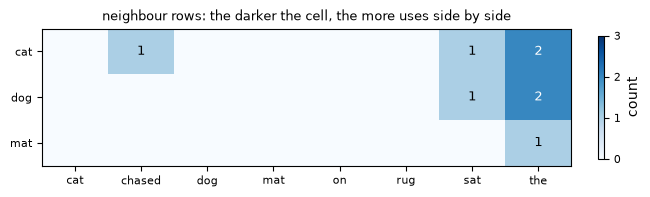

In [2]:
SHOW = ["cat", "dog", "mat"]
for word in SHOW:
    print(f"{word:>4}:", {w: int(n) for w, n in zip(WORDS, row(word)) if n})
counts_heatmap(SHOW)

### Solution

In [3]:
display(Markdown("`cat` stands after `the` twice, before `sat` once and before `chased` once. `dog` shares `the` and `sat` "
                 "with it; `mat` shares only `the`. `rug` has the same row as `mat`: both end a sentence after `the`."))

`cat` stands after `the` twice, before `sat` once and before `chased` once. `dog` shares `the` and `sat` with it; `mat` shares only `the`. `rug` has the same row as `mat`: both end a sentence after `the`.

## 2. Cosine compares two rows by their angle

The cosine of two rows is 1 when they point the same way and 0 when they have
no column in common. The left picture draws each row as an arrow at its angle
to `cat`. Run the cell: is `dog` or `mat` closer to `cat`? Then set `ONE_HOT`
to `True`, which gives each word a single 1 in its own column, and run it
again. Last, set `ONE_HOT` back to `False`, add `"the dog chased the cat"` to
`SENTENCES`, and run this cell and the cell of step 1 again.

cat and dog: cosine 0.913, angle 24.1 degrees
cat and mat: cosine 0.816, angle 35.3 degrees


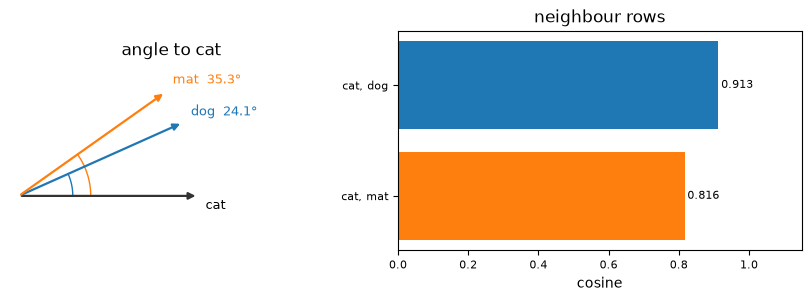

In [4]:
SENTENCES = ["the cat sat on the mat", "the dog sat on the rug", "the cat chased the dog"]
PAIRS = [("cat", "dog"), ("cat", "mat")]
ONE_HOT = False
compare(PAIRS, ONE_HOT)

### Solution

In [5]:
three = ["the cat sat on the mat", "the dog sat on the rug", "the cat chased the dog"]
four = three + ["the dog chased the cat"]
cos, deg = (lambda s, a, b: cosine(row(a, s), row(b, s))), (lambda v: np.degrees(np.arccos(min(v, 1))))
dog, mat, dog4, mat4 = cos(three, "cat", "dog"), cos(three, "cat", "mat"), cos(four, "cat", "dog"), cos(four, "cat", "mat")
display(Markdown(f"Counted company puts `dog` closer to `cat`: {dog:.3f} at {deg(dog):.1f} degrees against {mat:.3f} at "
                 f"{deg(mat):.1f} degrees. One-hot vectors give {cosine(one_hot('cat'), one_hot('dog')):g} for both: two "
                 "different words share no column, so both arrows stand at 90 degrees and one-hot vectors cannot say "
                 f"which is closer. With the fourth sentence `cat` and `dog` have the same row, {row('cat', four)[WORDS.index('the')]:g} "
                 f"times `the`, once `sat` and once `chased`: cosine {dog4:.3f}, the `dog` arrow on top of `cat`'s. "
                 f"`mat` rises to {mat4:.3f}, {deg(mat4):.1f} degrees, since `cat` now stands beside `the` more often."))

Counted company puts `dog` closer to `cat`: 0.913 at 24.1 degrees against 0.816 at 35.3 degrees. One-hot vectors give 0 for both: two different words share no column, so both arrows stand at 90 degrees and one-hot vectors cannot say which is closer. With the fourth sentence `cat` and `dog` have the same row, 3 times `the`, once `sat` and once `chased`: cosine 1.000, the `dog` arrow on top of `cat`'s. `mat` rises to 0.905, 25.2 degrees, since `cat` now stands beside `the` more often.